# Where Can London Still Afford to Buy?

## Notebook 01: Explore and clean

This notebook explores HM Land Registry Price Paid Data, decides which sales to keep, and produces a clean London dataset for analysis in MySQL.

**Audience:** a mortgage lender looking at affordability and market risk across London boroughs.

**Data:** HM Land Registry Price Paid Data, 2018 to 2026 (2026 is year to date). filtered toGreater London only.

## Business questions

1. What is the median price in each borough today?
2. How many years of local earnings does a median home cost, compared with a 4.5x mortgage?
3. How did prices change in each borough across three periods?
4. Did the pandemic shift demand from flats to houses, or from inner to outer London? Has that held since 2022?
5. Which boroughs are relatively affordable and still growing since rates rose?

## Periods

| Period | Years |
|---|---|
| Pre-COVID | 2018 to 2019 |
| Pandemic | 2020 to 2021 |
| Rate rises | 2022 to 2026 |

# values and explaination for fields

**Transaction unique identifier** :  A reference number which is generated automatically recording each published sale. The number is unique and will change each time a sale is recorded.

**Price** : Sale price stated on the transfer deed.

**Date of Transfer** : Date when the sale was completed, as stated on the transfer deed.

**Postcode** : This is the postcode used at the time of the original transaction. Note that postcodes can be reallocated and these changes are not reflected in the Price Paid Dataset.

**Property Type** : D = Detached, S = Semi-Detached, T = Terraced, F = Flats/Maisonettes, O = Other
Note that:
- we only record the above categories to describe property type, we do not separately identify bungalows
- end-of-terrace properties are included in the Terraced category above
- ‘Other’ is only valid where the transaction relates to a property type that is not covered by existing values, for example where a property comprises more than one large parcel of land

**OLD/NEW** : Indicates the age of the property and applies to all price paid transactions, residential and non-residential.
Y = a newly built property, N = an established residential building

**Duration** : Relates to the tenure: F = Freehold, L= Leasehold etc.
Note that HM Land Registry does not record leases of 7 years or less in the Price Paid Dataset.

**PAON** : Primary Addressable Object Name. Typically the house number or name.

**SAON** : Secondary Addressable Object Name. Where a property has been divided into separate units (for example, flats), the PAON (above) will identify the building and a SAON will be specified that identifies the separate unit/flat.

**PPD Category Type** : Indicates the type of Price Paid transaction.
A = Standard Price Paid entry, includes single residential property sold for value.
B = Additional Price Paid entry including transfers under a power of sale/repossessions, buy-to-lets (where they can be identified by a Mortgage), transfers to non-private individuals and sales where the property type is classed as ‘Other’.

Note that category B does not separately identify the transaction types stated.
HM Land Registry has been collecting information on Category A transactions from January 1995. Category B transactions were identified from October 2013.

**Record Status - monthly file only** : Indicates additions, changes and deletions to the records.(see guide below).
A = Addition
C = Change
D = Delete

Note that where a transaction changes category type due to misallocation (as above) it will be deleted from the original category type and added to the correct category with a new transaction unique identifier.


**taken from dataset instructions** https://www.gov.uk/guidance/about-the-price-paid-data

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [44]:
import pandas as pd

cols = [
    "transaction_id", "price", "date_of_transfer", "postcode",
    "property_type", "old_new", "duration", "paon", "saon",
    "street", "locality", "town_city", "district", "county",
    "ppd_category", "record_status",
]

df = pd.read_csv("../data/raw/pp-2025.csv", header=None, names=cols)
print(df.shape)
df.head(10)

(974087, 16)


,transaction_id,price,date_of_transfer,postcode,property_type,old_new,duration,paon,saon,street,locality,town_city,district,county,ppd_category,record_status
0,{402A3A66-B9C5-A7DF-E063-4804A8C0B80D},115000,2025-08-29 00:00,S42 5JL,T,N,F,4,NaN,NORTH STREET,NORTH WINGFIELD,CHESTERFIELD,NORTH EAST DERBYSHIRE,DERBYSHIRE,B,A
1,{402A3A66-B9C6-A7DF-E063-4804A8C0B80D},105000,2025-08-20 00:00,DE23 6SS,T,N,F,36,NaN,BELGRAVE STREET,NaN,DERBY,CITY OF DERBY,CITY OF DERBY,B,A
2,{402A3A66-B9C7-A7DF-E063-4804A8C0B80D},120000,2025-07-15 00:00,DE75 7RN,S,N,F,59,NaN,FLAMSTEAD AVENUE,LOSCOE,HEANOR,AMBER VALLEY,DERBYSHIRE,B,A
3,{402A3A66-B9C8-A7DF-E063-4804A8C0B80D},192500,2025-08-29 00:00,DE65 5GZ,D,N,F,93,NaN,WELLAND ROAD,HILTON,DERBY,SOUTH DERBYSHIRE,DERBYSHIRE,B,A
4,{402A3A66-B9C9-A7DF-E063-4804A8C0B80D},115000,2025-09-19 00:00,NG10 4LX,T,N,F,10,NaN,WELLINGTON STREET,LONG EATON,NOTTINGHAM,EREWASH,DERBYSHIRE,B,A
5,{402A3A66-B9CC-A7DF-E063-4804A8C0B80D},160000,2025-09-05 00:00,DE56 0HW,T,N,F,2,NaN,OVER LANE,NaN,BELPER,AMBER VALLEY,DERBYSHIRE,B,A
6,{402A3A66-B9CD-A7DF-E063-4804A8C0B80D},137500,2025-09-08 00:00,S41 0HB,S,N,F,27,NaN,VALLEY ROAD,NaN,CHESTERFIELD,CHESTERFIELD,DERBYSHIRE,B,A
7,{402A3A66-B9CE-A7DF-E063-4804A8C0B80D},76594,2025-08-07 00:00,DE23 6FR,F,N,L,"LIME HOUSE, 2",FLAT 3,LIME WALK,LITTLEOVER,DERBY,CITY OF DERBY,CITY OF DERBY,B,A
8,{402A3A66-B9CF-A7DF-E063-4804A8C0B80D},135000,2025-09-19 00:00,SK13 8BS,S,N,L,2 - 4,NORFOLK VIEW,NORFOLK STREET,NaN,GLOSSOP,HIGH PEAK,DERBYSHIRE,B,A
9,{402A3A66-B9D0-A7DF-E063-4804A8C0B80D},200000,2025-08-29 00:00,SK17 0TF,O,N,F,FLASH BAR STORES,NaN,NaN,QUARNFORD,BUXTON,HIGH PEAK,DERBYSHIRE,B,A


****values and explaination for fields****

**Transaction unique identifier** :  A reference number which is generated automatically recording each published sale. The number is unique and will change each time a sale is recorded.

**Price** : Sale price stated on the transfer deed.

**Date of Transfer** : Date when the sale was completed, as stated on the transfer deed.

**Postcode** : This is the postcode used at the time of the original transaction. Note that postcodes can be reallocated and these changes are not reflected in the Price Paid Dataset.

**Property Type** : D = Detached, S = Semi-Detached, T = Terraced, F = Flats/Maisonettes, O = Other
Note that:
- we only record the above categories to describe property type, we do not separately identify bungalows
- end-of-terrace properties are included in the Terraced category above
- ‘Other’ is only valid where the transaction relates to a property type that is not covered by existing values, for example where a property comprises more than one large parcel of land

**OLD/NEW** : Indicates the age of the property and applies to all price paid transactions, residential and non-residential.
Y = a newly built property, N = an established residential building

**Duration** : Relates to the tenure: F = Freehold, L= Leasehold etc.
Note that HM Land Registry does not record leases of 7 years or less in the Price Paid Dataset.

**PAON** : Primary Addressable Object Name. Typically the house number or name.

**SAON** : Secondary Addressable Object Name. Where a property has been divided into separate units (for example, flats), the PAON (above) will identify the building and a SAON will be specified that identifies the separate unit/flat.

**PPD Category Type** : Indicates the type of Price Paid transaction.
A = Standard Price Paid entry, includes single residential property sold for value.
B = Additional Price Paid entry including transfers under a power of sale/repossessions, buy-to-lets (where they can be identified by a Mortgage), transfers to non-private individuals and sales where the property type is classed as ‘Other’.

Note that category B does not separately identify the transaction types stated.
HM Land Registry has been collecting information on Category A transactions from January 1995. Category B transactions were identified from October 2013.

**Record Status - monthly file only** : Indicates additions, changes and deletions to the records.(see guide below).
A = Addition
C = Change
D = Delete

Note that where a transaction changes category type due to misallocation (as above) it will be deleted from the original category type and added to the correct category with a new transaction unique identifier.


In [45]:
pd.set_option("display.max_rows", None)
df["county"].value_counts().head(10)

county
GREATER LONDON        108179
GREATER MANCHESTER     45430
WEST YORKSHIRE         37747
WEST MIDLANDS          36741
KENT                   27841
ESSEX                  27125
LANCASHIRE             24465
HAMPSHIRE              23973
MERSEYSIDE             23342
SOUTH YORKSHIRE        22135
Name: count, dtype: int64

In [46]:
df["county"].nunique()

113

In [47]:
london = df[df["county"] == "GREATER LONDON"]
print(len(london), "London sales out of", len(df))
london["district"].value_counts()

108179 London sales out of 974087


district
WANDSWORTH                5785
CROYDON                   5214
BROMLEY                   5090
BARNET                    4706
LAMBETH                   4496
EALING                    3956
HAVERING                  3904
LEWISHAM                  3854
SOUTHWARK                 3787
WALTHAM FOREST            3575
ENFIELD                   3531
HILLINGDON                3529
TOWER HAMLETS             3495
BEXLEY                    3424
GREENWICH                 3322
HARINGEY                  3108
CITY OF WESTMINSTER       3105
RICHMOND UPON THAMES      3101
REDBRIDGE                 3019
HACKNEY                   2989
BRENT                     2967
HAMMERSMITH AND FULHAM    2960
MERTON                    2827
NEWHAM                    2809
SUTTON                    2802
HOUNSLOW                  2672
CAMDEN                    2613
HARROW                    2444
ISLINGTON                 2411
KINGSTON UPON THAMES      2316
KENSINGTON AND CHELSEA    2280
BARKING AND DAGENHAM      1846

In [48]:
london["property_type"].value_counts()

property_type
F    54232
T    28589
S    15160
O     5546
D     4652
Name: count, dtype: int64

In [49]:
london["ppd_category"].value_counts()

ppd_category
A    85904
B    22275
Name: count, dtype: int64

In [50]:
pd.set_option("display.float_format", "{:,.0f}".format)

In [51]:
london["price"].describe()

count       108,179
mean        762,874
std       3,098,634
min               1
25%         375,000
50%         510,000
75%         735,500
max     793,020,000
Name: price, dtype: float64

In [52]:
london_share = len(london) / len(df) * 100
print(f"London is {london_share:.1f}% of all sales in 2025")

London is 11.1% of all sales in 2025


In [53]:
(london["property_type"].value_counts() / len(london) * 100)

property_type
F   50
T   26
S   14
O    5
D    4
Name: count, dtype: float64

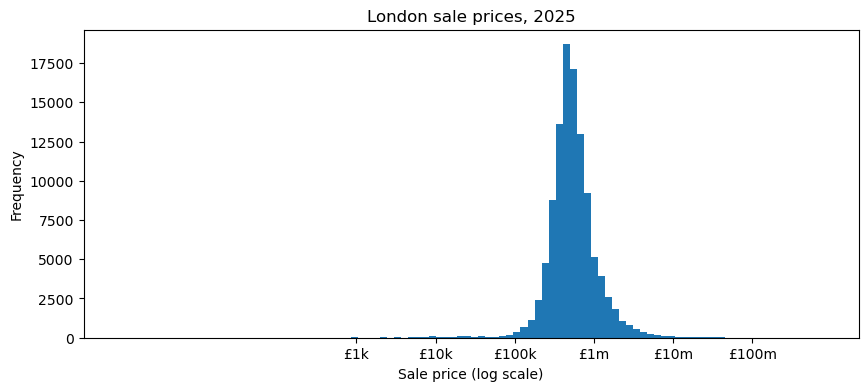

In [64]:
np.log10(london["price"]).plot(kind="hist", bins=100, figsize=(10, 4),
                               title="London sale prices, 2025")
plt.xticks([3, 4, 5, 6, 7, 8], ["£1k", "£10k", "£100k", "£1m", "£10m", "£100m"])
plt.xlabel("Sale price (log scale)")
plt.show()

In [59]:
london[london["property_type"] == "D"]["district"].value_counts()

district
BROMLEY                   779
CROYDON                   543
BARNET                    375
HILLINGDON                371
HAVERING                  369
SUTTON                    230
KINGSTON UPON THAMES      228
BEXLEY                    199
HARROW                    194
RICHMOND UPON THAMES      183
ENFIELD                   172
REDBRIDGE                 130
EALING                    123
BRENT                     101
MERTON                     90
GREENWICH                  87
HOUNSLOW                   81
WANDSWORTH                 56
LEWISHAM                   55
CAMDEN                     49
SOUTHWARK                  42
WALTHAM FOREST             40
HARINGEY                   35
LAMBETH                    30
KENSINGTON AND CHELSEA     19
BARKING AND DAGENHAM       16
CITY OF WESTMINSTER        13
HACKNEY                    11
ISLINGTON                  10
HAMMERSMITH AND FULHAM     10
NEWHAM                      8
TOWER HAMLETS               3
Name: count, dtype: int64

In [60]:
london[london["property_type"] == "D"]["district"].nunique()

32

32 out of 33 borough have sales of detached houses in 2025 city of lodon has none here we group terraced, detached and semi detached int houses

In [61]:
london = df[df["county"] == "GREATER LONDON"].copy()

london["home_type"] = london["property_type"].map(
    {"F": "Flat", "T": "House", "S": "House", "D": "House"}
)

london["home_type"].value_counts(normalize=True, dropna=False).mul(100).round(1)

home_type
Flat    50
House   45
NaN      5
Name: proportion, dtype: float64

## Step 1: London share and property types

**Finding:** London had 108,179 of the 974,087 sales in England and Wales in 2025 (11.1%). Half of London sales were flats (50%), followed by terraced (26%), semi-detached (14%), other (5%) and detached (4%).

Detached sales are too thin to analyse by borough. Tower Hamlets had 3 detached sales in 2025, and the City of London had none. A median based on a handful of sales would move around a lot from year to year.

**Decision:**
- Group detached, semi-detached and terraced into one "House" category, and compare houses with flats.
- Drop property type "O" (other). It covers non-residential sales like commercial units and land, which don't fit a question about the cost of a home.

In [68]:
(london["ppd_category"].value_counts(normalize=True) * 100).round(1)

ppd_category
A   79
B   21
Name: proportion, dtype: float64

In [66]:
london.groupby("ppd_category")["price"].describe()[["count", "50%", "mean", "max"]]

,count,50%,mean,max
ppd_category,,,,
A,"85,904","530,000","702,173","53,000,000"
B,"22,275","425,000","996,968","793,020,000"


In [69]:
(pd.crosstab(london["property_type"], london["ppd_category"], normalize="index") * 100).round(1)

ppd_category,A,B
property_type,,
D,89,11
F,82,18
O,0,100
S,88,12
T,84,16


Step 2 decision: Keep category A only. Category B is 21% of London sales in 2025 and covers repossessions, company buyers and bulk transfers. Its median is £105k below category A, and its maximum (£793m) is a multi property transfer, not a single home. All type O sales are category B, so this filter also removes them. Flats have the highest B share (18% vs 11% for detached), so the clean data slightly under-represents flats bought by companies and investors.

In [70]:
in_scope = london[(london["ppd_category"] == "A") & (london["property_type"] != "O")]
print(len(in_scope), "in-scope rows")
in_scope["price"].describe()

85904 in-scope rows


count       85,904
mean       702,173
std        801,317
min              1
25%        400,000
50%        530,000
75%        755,000
max     53,000,000
Name: price, dtype: float64

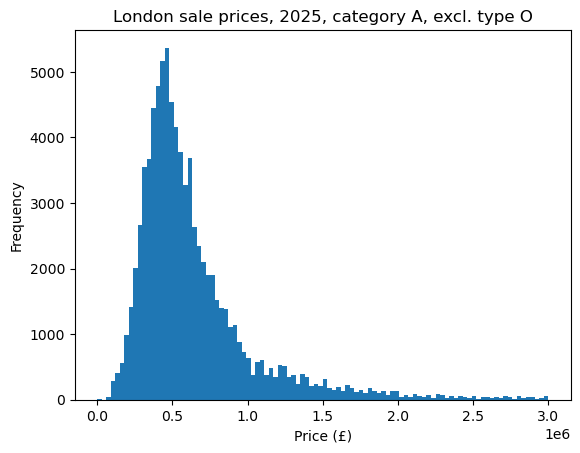

In [72]:
in_scope["price"].plot(kind="hist", bins=100, range=(0, 3_000_000))
plt.xlabel("Price (£)")
plt.title("London sale prices, 2025, category A, excl. type O")
plt.show()

Step 3 decision: Use the median, not the mean. Prices are right skewed: most 2025 sales sit between £400k and £755k, with a long tail of expensive homes. The mean (£702k) is £172k above the median (£530k) because of that tail. The median is also what ONS uses, so results can be compared with official figures.

in this step we aim to remove the outliers, and IQR method will not be ideal as in this scenario as a naturally more expensive homes in expensive borouhgs such as kensington and hampstead will get eliminated.

In [74]:
print("Under £50k:", (in_scope["price"] < 50_000).sum())
print("Over £10m:", (in_scope["price"] > 10_000_000).sum())

Under £50k: 5
Over £10m: 70


In [75]:
cols_to_see = ["price", "date_of_transfer", "property_type", "postcode", "district", "street", "paon", "saon"]
in_scope[in_scope["price"] < 50_000].sort_values("price")[cols_to_see].head(15)

,price,date_of_transfer,property_type,postcode,district,street,paon,saon
323169,1,2025-04-01 00:00,F,SW18 2HG,WANDSWORTH,EAST HILL,80A,NaN
323170,1,2025-04-01 00:00,F,SW18 2HG,WANDSWORTH,EAST HILL,80,FLAT 2
323171,1,2025-04-01 00:00,F,SW18 2HG,WANDSWORTH,EAST HILL,80,FLAT 3
323172,1,2025-04-01 00:00,F,SW18 2HG,WANDSWORTH,EAST HILL,80,FLAT 4
395647,8000,2025-10-27 00:00,F,UB5 4PE,EALING,DORCHESTER CLOSE,18,NaN


In [76]:
in_scope[in_scope["price"] > 10_000_000].sort_values("price", ascending=False)[cols_to_see].head(15)

,price,date_of_transfer,property_type,postcode,district,street,paon,saon
207827,53000000,2025-09-03 00:00,D,NW8 6JD,CAMDEN,AVENUE ROAD,87,NaN
630258,41000000,2025-06-27 00:00,D,W11 3TH,KENSINGTON AND CHELSEA,HOLLAND PARK,12,NaN
902549,34000000,2025-12-15 00:00,F,SW1X 7LJ,CITY OF WESTMINSTER,KNIGHTSBRIDGE,"ONE HYDE PARK, 100",APARTMENT C.05.1
176080,34000000,2025-01-31 00:00,T,SW1X 8RN,CITY OF WESTMINSTER,WILTON CRESCENT,4,NaN
784872,32000000,2025-01-15 00:00,D,NW8 6HH,CAMDEN,QUEENS GROVE,42,NaN
794313,28500000,2025-01-31 00:00,D,W14 8EB,KENSINGTON AND CHELSEA,ADDISON ROAD,77,NaN
65624,25900000,2025-08-22 00:00,D,N6 6NA,CAMDEN,MERTON LANE,HEATHFIELD PARK,NaN
785678,25880000,2025-01-08 00:00,D,NW8 6HS,CAMDEN,AVENUE ROAD,36,NaN
171078,24500000,2025-05-15 00:00,T,SW3 5QZ,KENSINGTON AND CHELSEA,CHEYNE WALK,9,NaN
396481,24000000,2025-01-15 00:00,S,W11 2NJ,KENSINGTON AND CHELSEA,LANSDOWNE CRESCENT,14,NaN


Step 4 decision: Exclude sales under £10,000. In 2025 there were only 5 sales under £50k and none were real market sales: four flats in one Wandsworth building each sold for £1 on the same day (a paperwork transfer), and one flat in Ealing sold for £8,000. Keep sales over £10m. There were 70, all in prime areas like St John’s Wood, Holland Park and Knightsbridge, and they look genuine. They make up 0.08% of sales and don’t affect medians.

In [78]:
print(in_scope["district"].nunique(), "unique districts")
in_scope["district"].value_counts()

33 unique districts


district
WANDSWORTH                5059
BROMLEY                   4462
CROYDON                   3986
LAMBETH                   3802
BARNET                    3607
HAVERING                  3237
LEWISHAM                  3151
SOUTHWARK                 3127
WALTHAM FOREST            2986
BEXLEY                    2939
EALING                    2863
RICHMOND UPON THAMES      2752
TOWER HAMLETS             2731
GREENWICH                 2712
ENFIELD                   2619
HILLINGDON                2497
SUTTON                    2425
HARINGEY                  2425
MERTON                    2346
HAMMERSMITH AND FULHAM    2296
HACKNEY                   2283
REDBRIDGE                 2258
CITY OF WESTMINSTER       2164
HOUNSLOW                  2141
BRENT                     2088
NEWHAM                    2032
ISLINGTON                 2017
CAMDEN                    1980
KINGSTON UPON THAMES      1962
KENSINGTON AND CHELSEA    1737
HARROW                    1695
BARKING AND DAGENHAM      1364

**Step 5 decision: boroughs**

- district holds all 33 London areas (32 boroughs plus the City of London), with no spelling issues.
- Sales per borough in 2025 range from 5,059 (Wandsworth) to 1,364 (Barking and Dagenham).
- The City of London had only 161 sales. Keep it, but only report a median where a group has at least 30 sales, so small splits don't produce unreliable numbers.

In [79]:
in_scope.isna().sum()

transaction_id          0
price                   0
date_of_transfer        0
postcode               25
property_type           0
old_new                 0
duration                0
paon                    0
saon                55084
street                  5
locality            80189
town_city               0
district                0
county                  0
ppd_category            0
record_status           0
home_type               0
dtype: int64

In [80]:
print("Duplicate transaction IDs:", in_scope["transaction_id"].duplicated().sum())
in_scope["record_status"].value_counts()

Duplicate transaction IDs: 0


record_status
A    85904
Name: count, dtype: int64

**Step 6 decision: data quality**

- No missing values in the columns used for analysis: price, date, property type, category and district.
- Missing values elsewhere are expected: `saon` is blank for houses (no flat number), `locality` is optional, and 25 rows have no postcode. Analysis is at borough level, so all rows are kept.
- No duplicate transaction IDs. All rows have record status A, because yearly files already include corrections and deletions.

In [81]:
print(in_scope["date_of_transfer"].dtype)
print(in_scope["date_of_transfer"].min(), "to", in_scope["date_of_transfer"].max())

object
2025-01-01 00:00 to 2025-12-31 00:00


/var/folders/pq/v8d69d551x77sdlmg2lmp_3h0000gn/T/ipykernel_9639/186507945.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  in_scope["date_of_transfer"] = pd.to_datetime(in_scope["date_of_transfer"])


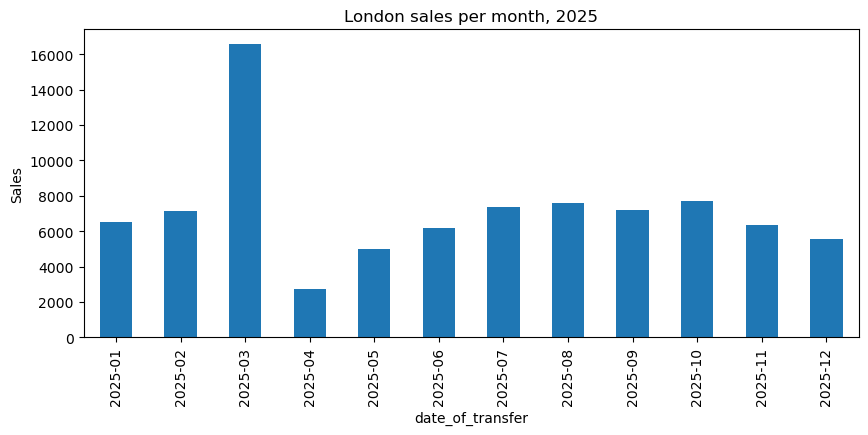

In [83]:
in_scope["date_of_transfer"] = pd.to_datetime(in_scope["date_of_transfer"])

monthly = in_scope.groupby(in_scope["date_of_transfer"].dt.to_period("M")).size()
monthly.plot(kind="bar", figsize=(10, 4), title="London sales per month, 2025")
plt.ylabel("Sales")
plt.show()